In [59]:
import pandas as pd  
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer 
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler , MinMaxScaler



In [60]:
df = pd.read_csv("Titanic-Dataset.csv")

In [61]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [62]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [63]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [64]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [65]:
num_cols = ["Age"]
cat_cols = ["Embarked"]


In [66]:
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [67]:

num_pipe = Pipeline([
    ("imputer" , SimpleImputer(strategy="median"))
])

In [68]:
cat_pipe = Pipeline([
 ("imputer", SimpleImputer(strategy="most_frequent"))
])

In [69]:
prep = ColumnTransformer([
    ("numerique",num_pipe, num_cols),
    ("categorial",cat_pipe, cat_cols)
])

df[num_cols] = num_pipe.fit_transform(df[num_cols])

In [70]:
df.isna().sum() 

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [71]:
df.drop('Cabin', axis=1, inplace=True)

df.isna().sum() 

    


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64

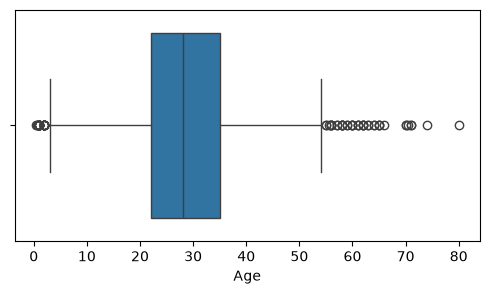

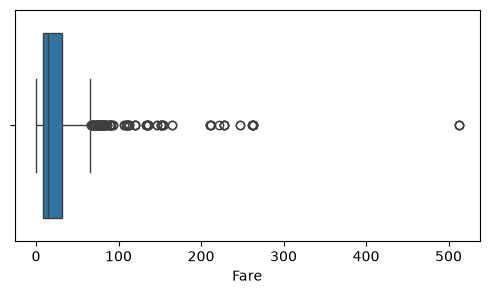

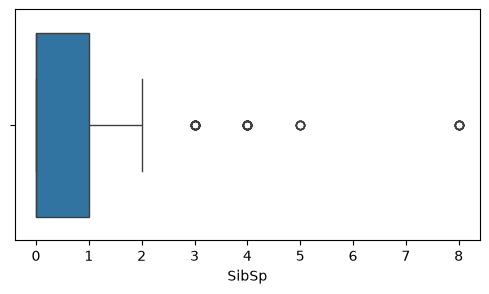

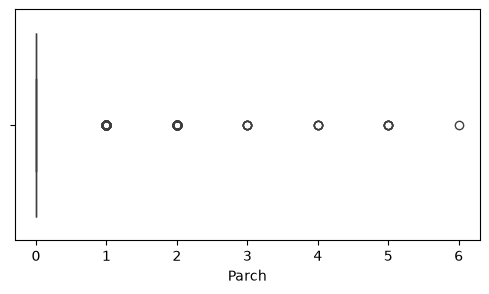

In [72]:
numeric_cols = ["Age", "Fare", "SibSp", "Parch"]
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.show()


In [73]:

for col in numeric_cols:
    if col in ["SibSp", "Parch"]:
        continue
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    li = Q1 - 1.5 * IQR
    ls = Q3 + 1.5 * IQR
    median = df[col].median()
    df.loc[(df[col] < li) | (df[col] > ls), col] = median
    print(f"{col} : [{li}, {ls}]")

Age : [2.5, 54.5]
Fare : [-26.724, 65.6344]


In [74]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Embarked           str
dtype: object

In [75]:
c_cols = ['Sex','Embarked']


In [76]:
c_pipe = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
encodage = c_pipe.fit_transform(df[c_cols])

In [77]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Embarked           str
dtype: object

In [78]:
stand_cols = ['Age', 'SibSp', 'Parch', 'Fare']
norme = MinMaxScaler()

df_norme = df.copy()

df_norme[stand_cols] = norme.fit_transform(df[stand_cols])

In [79]:


scaler = StandardScaler()

df_stand = df.copy()

df_stand[stand_cols] = scaler.fit_transform(df[stand_cols])


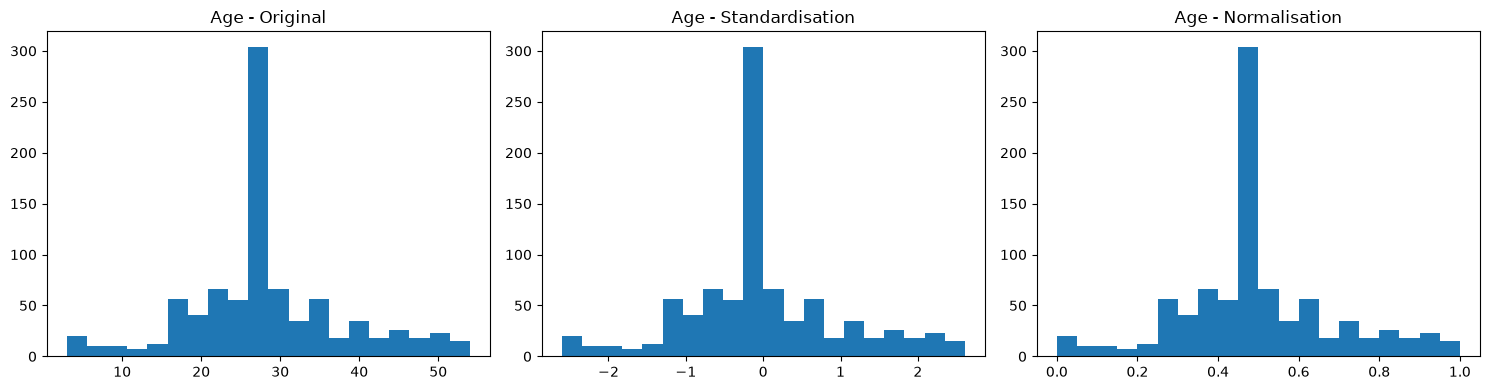

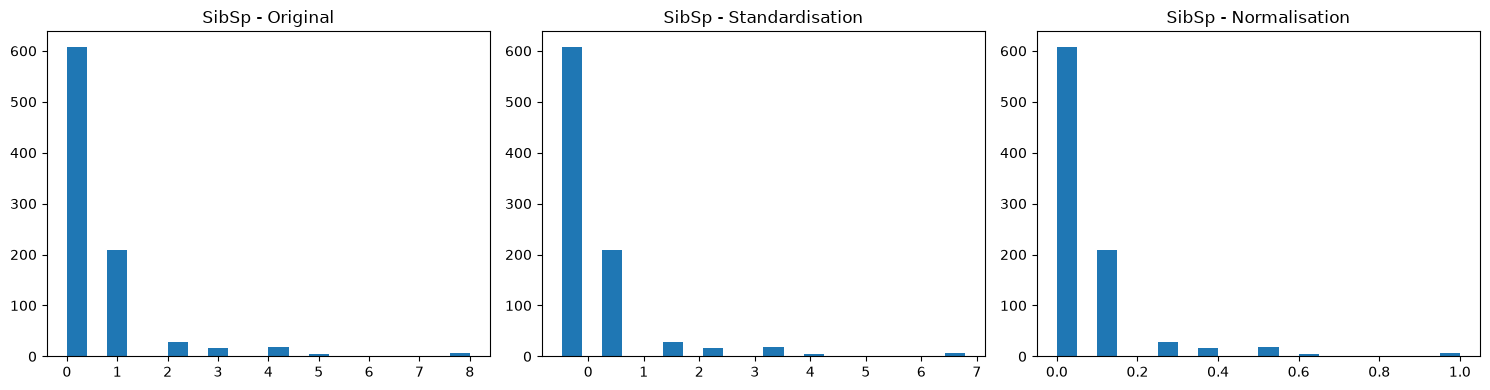

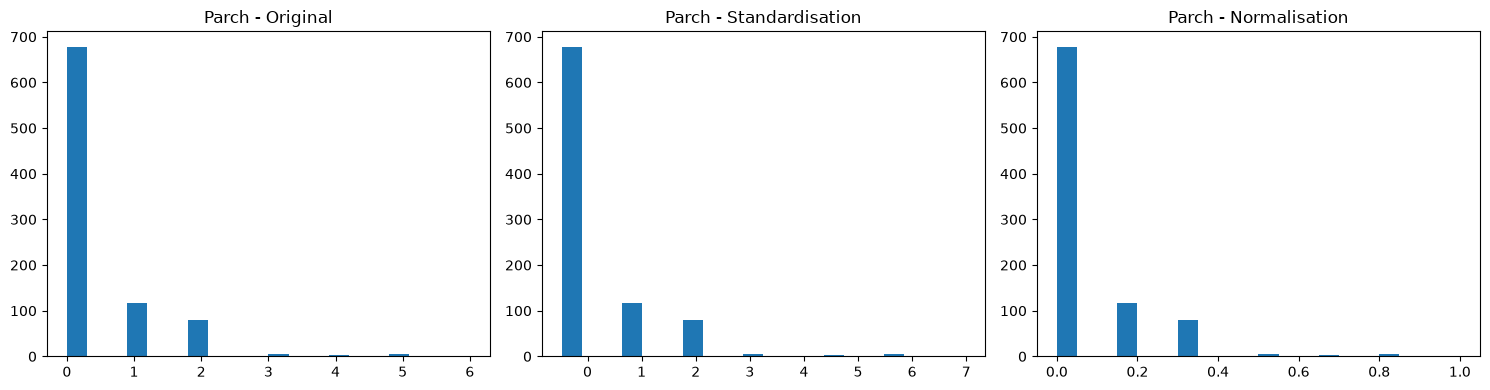

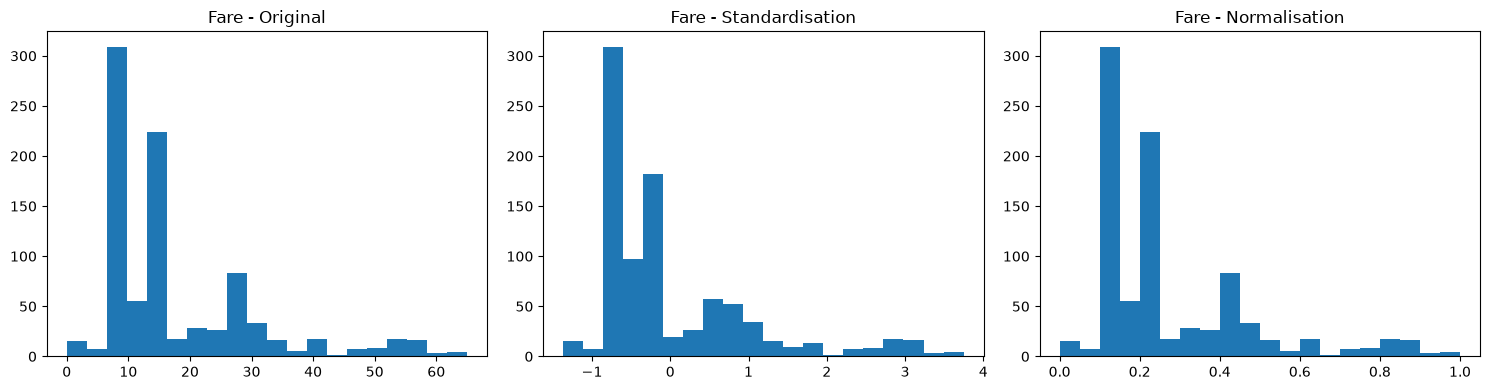

In [80]:
for col in stand_cols:

    plt.figure(figsize=(15, 4))  
    
    plt.subplot(1, 3, 1)
    plt.hist(df[col], bins=20)
    plt.title(f'{col} - Original')

    plt.subplot(1, 3, 2)
    plt.hist(df_stand[col], bins=20)
    plt.title(f'{col} - Standardisation')

    plt.subplot(1, 3, 3)
    plt.hist(df_norme[col], bins=20)
    plt.title(f'{col} - Normalisation')

    plt.tight_layout()
    plt.show()

In [81]:
df['Survived'].value_counts()


Survived
0    549
1    342
Name: count, dtype: int64

In [82]:
majority = df[df['Survived'] == 0]
minority = df[df['Survived'] == 1]

In [83]:
majority_ = majority.sample(n=342, random_state=42)

In [84]:
df_under = pd.concat([majority_, minority])

In [85]:
df_under['Survived'].value_counts()

Survived
0    342
1    342
Name: count, dtype: int64